/tmp/ipykernel_3494/1824775225.py:8: UserWarning: Parsing dates in %d/%m/%Y format when dayfirst=False (the default) was specified. Pass `dayfirst=True` or specify a format to silence this warning.
  df['Date'] = pd.to_datetime(df['Date'])


Date          datetime64[ns]
Symbol                object
Series                object
Prev Close           float64
Open                 float64
High                 float64
Low                  float64
Last                 float64
Close                float64
VWAP                 float64
dtype: object


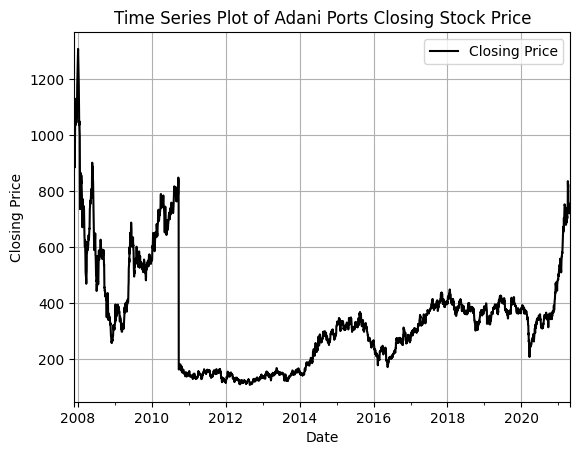

In [1]:
from matplotlib import pyplot as plt
import pandas as pd

df = pd.read_csv("/content/ADANIPORTS-selected-columns.csv")

df.head()

df['Date'] = pd.to_datetime(df['Date'])

print(df.dtypes)

df = df.sort_values('Date')

df = df.set_index('Date')

df_resampled = df['Close'].resample('B').last()

df_resampled = df_resampled.interpolate(method='time', limit_area='inside')

df_resampled.plot(kind='line', label='Closing Price', color='black')

plt.title('Time Series Plot of Adani Ports Closing Stock Price')
plt.xlabel('Date')
plt.ylabel('Closing Price')
plt.legend()
plt.grid(True)
plt.show()


/tmp/ipykernel_955/3344413541.py:9: UserWarning: Parsing dates in %d/%m/%Y format when dayfirst=False (the default) was specified. Pass `dayfirst=True` or specify a format to silence this warning.
  data['Date'] = pd.to_datetime(data['Date'])


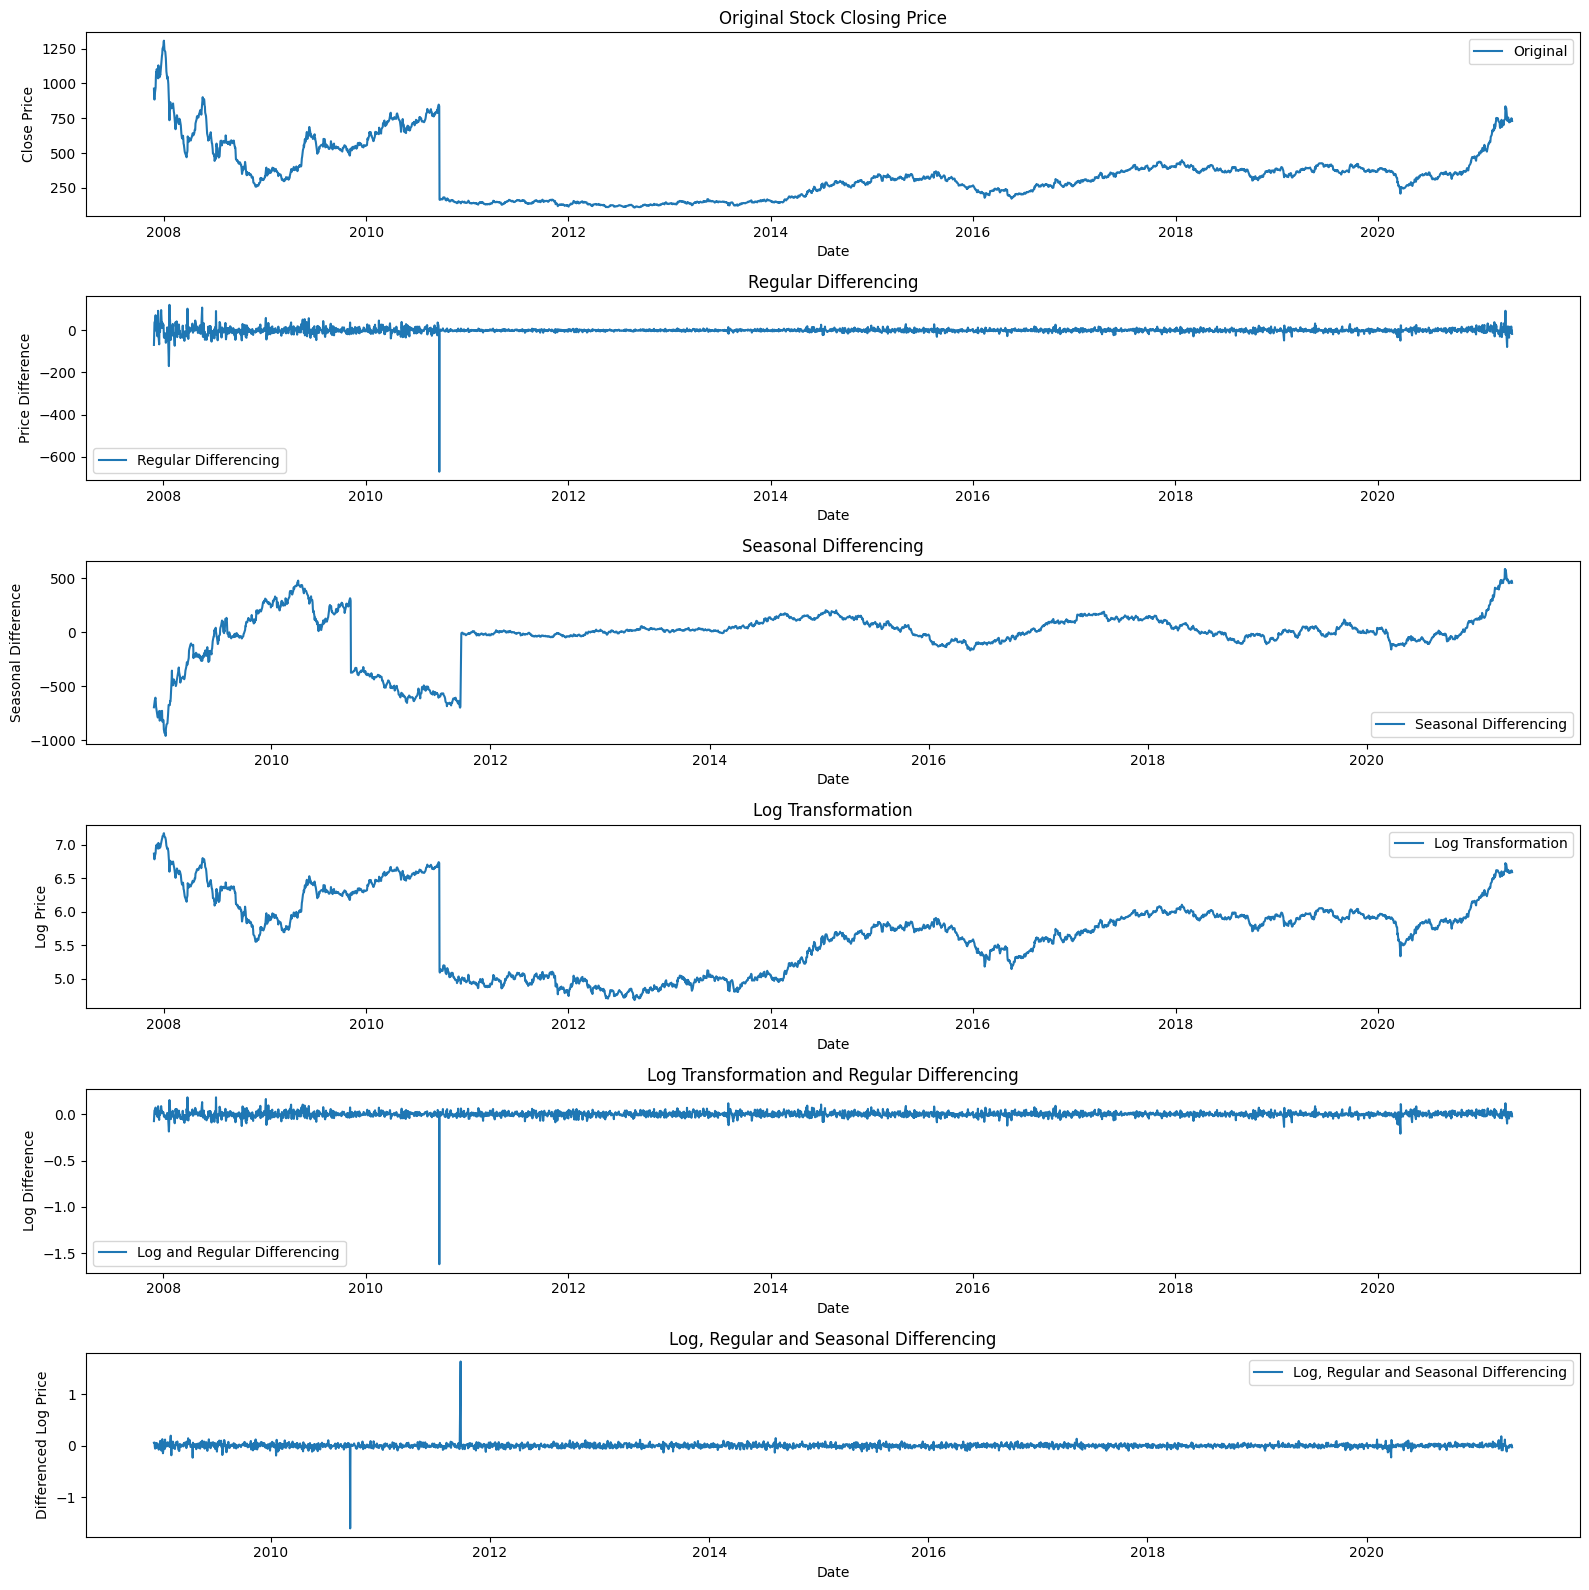

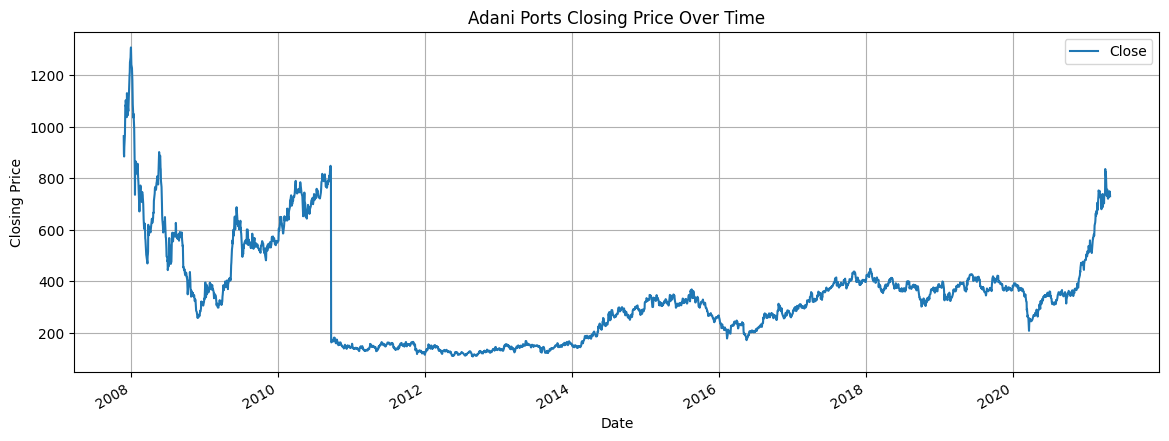

In [ ]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

data = pd.read_csv('/content/ADANIPORTS-selected-columns.csv')

data.head()

data['Date'] = pd.to_datetime(data['Date'])

data = data.sort_values('Date')
data = data.drop_duplicates(subset='Date', keep='last')
data = data.set_index('Date')

data['Close'] = pd.to_numeric(data['Close'], errors='coerce')
data = data.dropna(subset=['Close'])

data['price_diff'] = data['Close'].diff()

period = 252

data['price_seasonal_diff'] = data['Close'].diff(period)

data['price_log'] = np.log(data['Close'].where(data['Close'] > 0))

data['price_log_diff'] = data['price_log'].diff()

data['price_log_seasonal_diff'] = data['price_log'].diff(period)

data['price_log_regular_seasonal_diff'] = (
    data['price_log'].diff().diff(period)
)

plt.figure(figsize=(16, 16))

plt.subplot(6, 1, 1)
plt.plot(data['Close'], label='Original')
plt.legend(loc='best')
plt.title('Original Stock Closing Price')
plt.xlabel('Date')
plt.ylabel('Close Price')

plt.subplot(6, 1, 2)
plt.plot(data['price_diff'], label='Regular Differencing')
plt.legend(loc='best')
plt.title('Regular Differencing')
plt.xlabel('Date')
plt.ylabel('Price Difference')

plt.subplot(6, 1, 3)
plt.plot(data['price_seasonal_diff'], label='Seasonal Differencing')
plt.legend(loc='best')
plt.title('Seasonal Differencing')
plt.xlabel('Date')
plt.ylabel('Seasonal Difference')

plt.subplot(6, 1, 4)
plt.plot(data['price_log'], label='Log Transformation')
plt.legend(loc='best')
plt.title('Log Transformation')
plt.xlabel('Date')
plt.ylabel('Log Price')

plt.subplot(6, 1, 5)
plt.plot(data['price_log_diff'], label='Log and Regular Differencing')
plt.legend(loc='best')
plt.title('Log Transformation and Regular Differencing')
plt.xlabel('Date')
plt.ylabel('Log Difference')

plt.subplot(6, 1, 6)
plt.plot(
    data['price_log_regular_seasonal_diff'],
    label='Log, Regular and Seasonal Differencing'
)
plt.legend(loc='best')
plt.title('Log, Regular and Seasonal Differencing')
plt.xlabel('Date')
plt.ylabel('Differenced Log Price')

plt.tight_layout()
plt.show()

data.plot(kind='line', y='Close', figsize=(14, 5))
plt.title('Adani Ports Closing Price Over Time')
plt.xlabel('Date')
plt.ylabel('Closing Price')
plt.grid(True)
plt.show()

/tmp/ipykernel_3494/1594637955.py:8: UserWarning: Parsing dates in %d/%m/%Y format when dayfirst=False (the default) was specified. Pass `dayfirst=True` or specify a format to silence this warning.
  data['Date'] = pd.to_datetime(data['Date'])


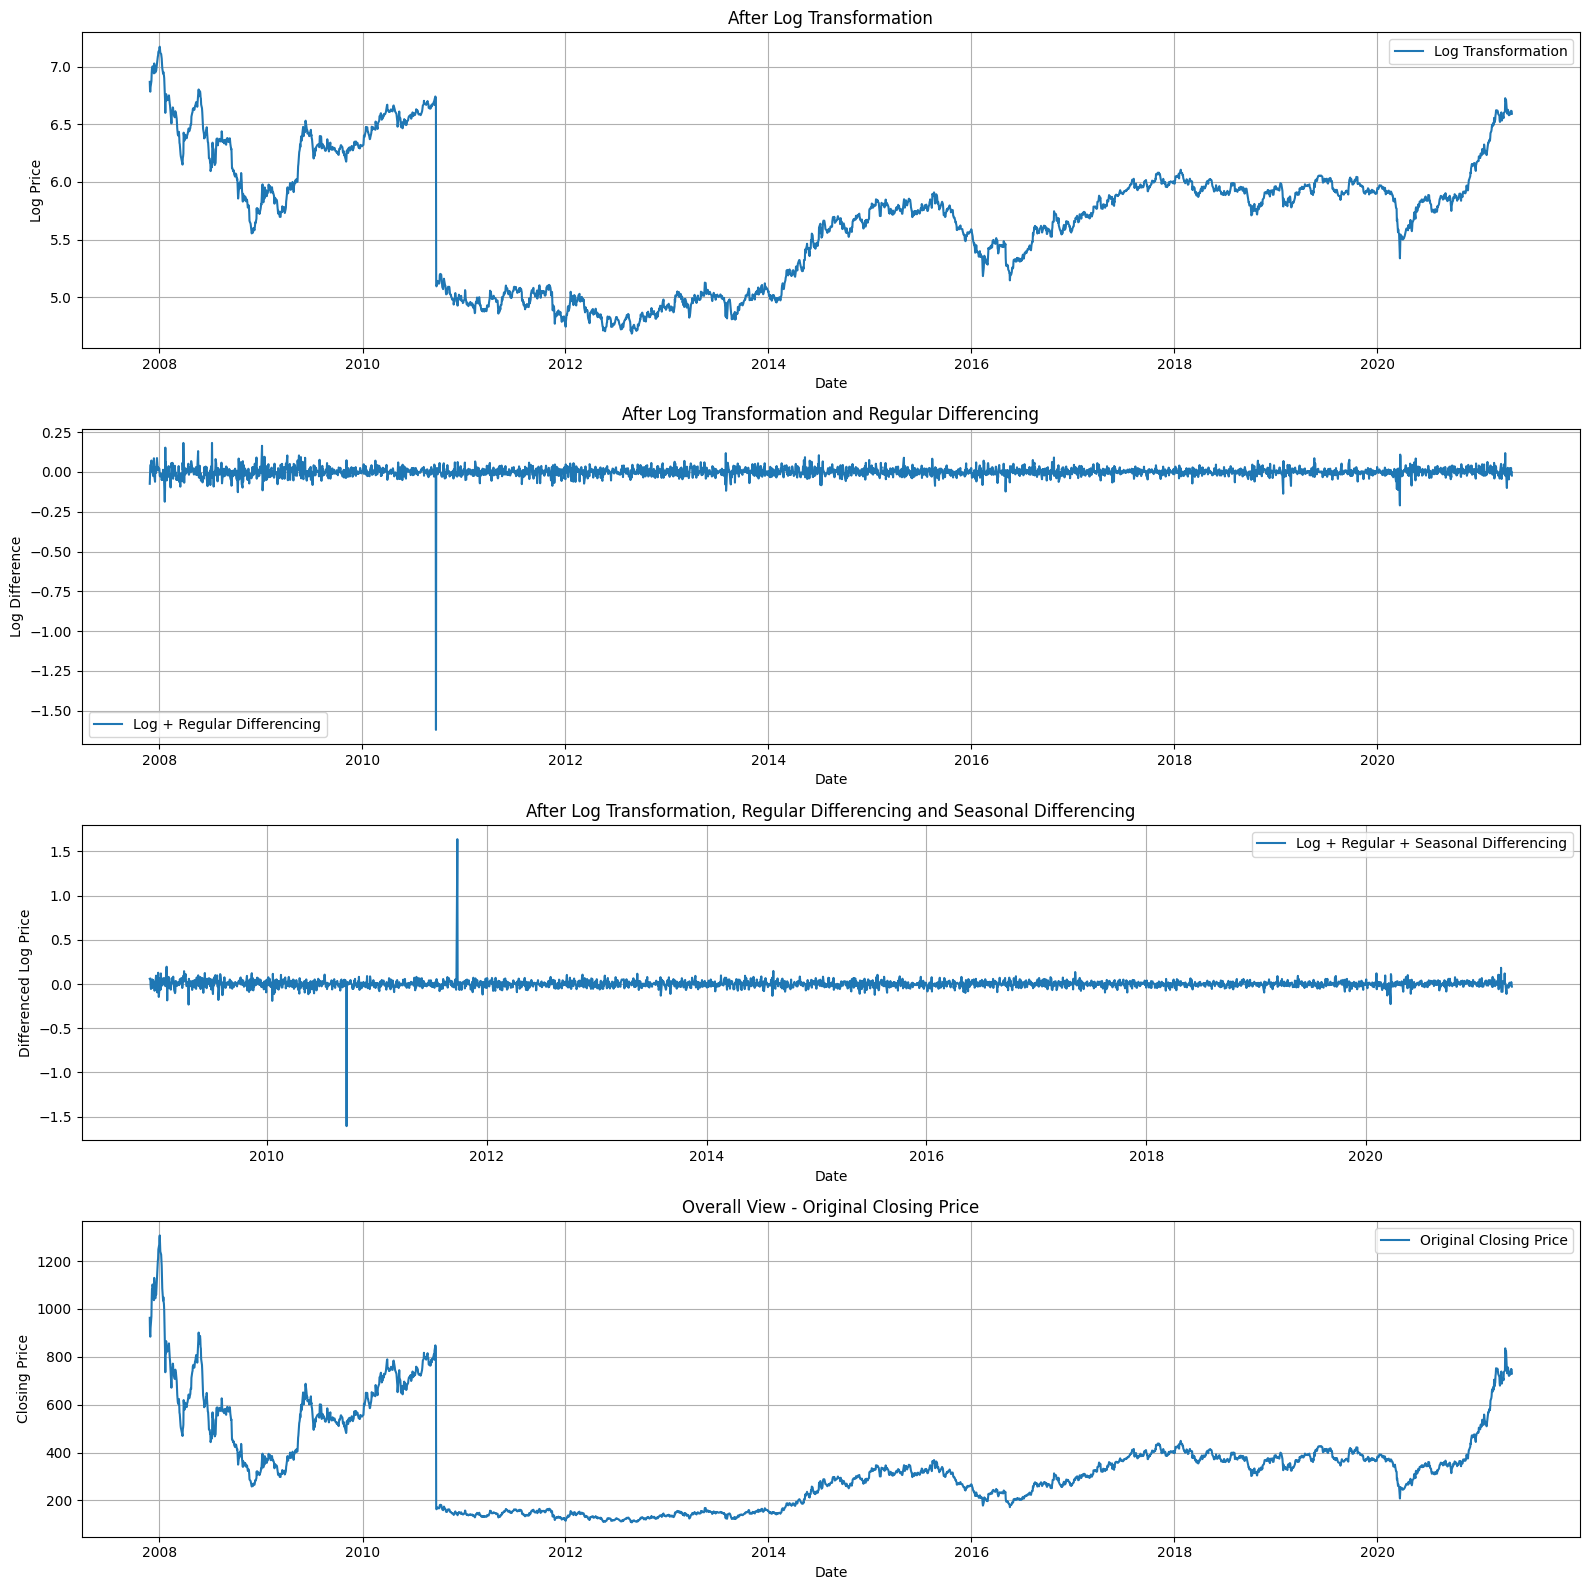

/tmp/ipykernel_3494/1594637955.py:68: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  result = adfuller(series_clean)


=== ADF Test: Original Close ===
ADF Statistic: -3.4731
p-value: 8.7055e-03
Conclusion: Stationary (Reject Null Hypothesis at 5% level)



/tmp/ipykernel_3494/1594637955.py:68: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  result = adfuller(series_clean)


=== ADF Test: Log Transformed ===
ADF Statistic: -2.2749
p-value: 1.8020e-01
Conclusion: Non-Stationary (Fail to Reject Null Hypothesis at 5% level)



/tmp/ipykernel_3494/1594637955.py:68: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  result = adfuller(series_clean)


=== ADF Test: Log + Regular Differencing ===
ADF Statistic: -57.2201
p-value: 0.0000e+00
Conclusion: Stationary (Reject Null Hypothesis at 5% level)

=== ADF Test: Log + Regular + Seasonal Differencing ===
ADF Statistic: -54.7420
p-value: 0.0000e+00
Conclusion: Stationary (Reject Null Hypothesis at 5% level)



/tmp/ipykernel_3494/1594637955.py:68: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  result = adfuller(series_clean)


In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from statsmodels.tsa.stattools import adfuller

data = pd.read_csv('/content/ADANIPORTS-selected-columns.csv')

data['Date'] = pd.to_datetime(data['Date'])
data = data.sort_values('Date')
data = data.drop_duplicates(subset='Date', keep='last')
data = data.set_index('Date')

data['Close'] = pd.to_numeric(data['Close'], errors='coerce')
data = data.dropna(subset=['Close'])

data['price_log'] = np.log(data['Close'])
data['price_log_diff'] = data['price_log'].diff()

period = 252
data['price_log_seasonal_diff'] = data['price_log'].diff(period)
data['price_log_regular_seasonal_diff'] = (
    data['price_log'].diff().diff(period)
)

plt.figure(figsize=(16, 16))

plt.subplot(4, 1, 1)
plt.plot(data['price_log'], label='Log Transformation')
plt.title('After Log Transformation')
plt.xlabel('Date')
plt.ylabel('Log Price')
plt.legend()
plt.grid(True)

plt.subplot(4, 1, 2)
plt.plot(data['price_log_diff'], label='Log + Regular Differencing')
plt.title('After Log Transformation and Regular Differencing')

plt.xlabel('Date')
plt.ylabel('Log Difference')
plt.legend()
plt.grid(True)

plt.subplot(4, 1, 3)
plt.plot(
    data['price_log_regular_seasonal_diff'],
    label='Log + Regular + Seasonal Differencing'
)
plt.title('After Log Transformation, Regular Differencing and Seasonal Differencing')
plt.xlabel('Date')
plt.ylabel('Differenced Log Price')
plt.legend()
plt.grid(True)

plt.subplot(4, 1, 4)
plt.plot(data['Close'], label='Original Closing Price')
plt.title('Overall View - Original Closing Price')
plt.xlabel('Date')
plt.ylabel('Closing Price')
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()

def print_adf_result(series, name):
    series_clean = series.dropna()
    result = adfuller(series_clean)
    print(f'=== ADF Test: {name} ===')
    print(f'ADF Statistic: {result[0]:.4f}')
    print(f'p-value: {result[1]:.4e}')
    if result[1] <= 0.05:
        print('Conclusion: Stationary (Reject Null Hypothesis at 5% level)\n')
    else:
        print('Conclusion: Non-Stationary (Fail to Reject Null Hypothesis at 5% level)\n')

print_adf_result(data['Close'], 'Original Close')
print_adf_result(data['price_log'], 'Log Transformed')
print_adf_result(data['price_log_diff'], 'Log + Regular Differencing')
print_adf_result(data['price_log_regular_seasonal_diff'], 'Log + Regular + Seasonal Differencing')

In [5]:
from statsmodels.tsa.stattools import adfuller
import warnings
warnings.filterwarnings('ignore')

def print_stationarity_report(series, name):
    cleaned = series.dropna()
    result = adfuller(cleaned)
    print(f"--- ADF Test for: {name} ---")
    print(f"ADF Statistic: {result[0]:.4f}")
    print(f"p-value: {result[1]:.4e}")
    if result[1] <= 0.05:
        print("Status: STATIONARY (Reject Null Hypothesis of unit root at 5% level)")
    else:
        print("Status: NON-STATIONARY (Fail to reject Null Hypothesis)")
    print("-" * 40)

print_stationarity_report(data['Close'], 'Original Closing Price')
print_stationarity_report(data['price_log'], 'Log Price')
print_stationarity_report(data['price_log_diff'], 'Log Return (1st Difference)')
print_stationarity_report(data['price_log_regular_seasonal_diff'], 'Log + Regular + Seasonal Difference')

--- ADF Test for: Original Closing Price ---
ADF Statistic: -3.4731
p-value: 8.7055e-03
Status: STATIONARY (Reject Null Hypothesis of unit root at 5% level)
----------------------------------------
--- ADF Test for: Log Price ---
ADF Statistic: -2.2749
p-value: 1.8020e-01
Status: NON-STATIONARY (Fail to reject Null Hypothesis)
----------------------------------------
--- ADF Test for: Log Return (1st Difference) ---
ADF Statistic: -57.2201
p-value: 0.0000e+00
Status: STATIONARY (Reject Null Hypothesis of unit root at 5% level)
----------------------------------------
--- ADF Test for: Log + Regular + Seasonal Difference ---
ADF Statistic: -54.7420
p-value: 0.0000e+00
Status: STATIONARY (Reject Null Hypothesis of unit root at 5% level)
----------------------------------------


/tmp/ipykernel_3494/2162283602.py:7: UserWarning: Parsing dates in %d/%m/%Y format when dayfirst=False (the default) was specified. Pass `dayfirst=True` or specify a format to silence this warning.
  data['Date'] = pd.to_datetime(data['Date'])


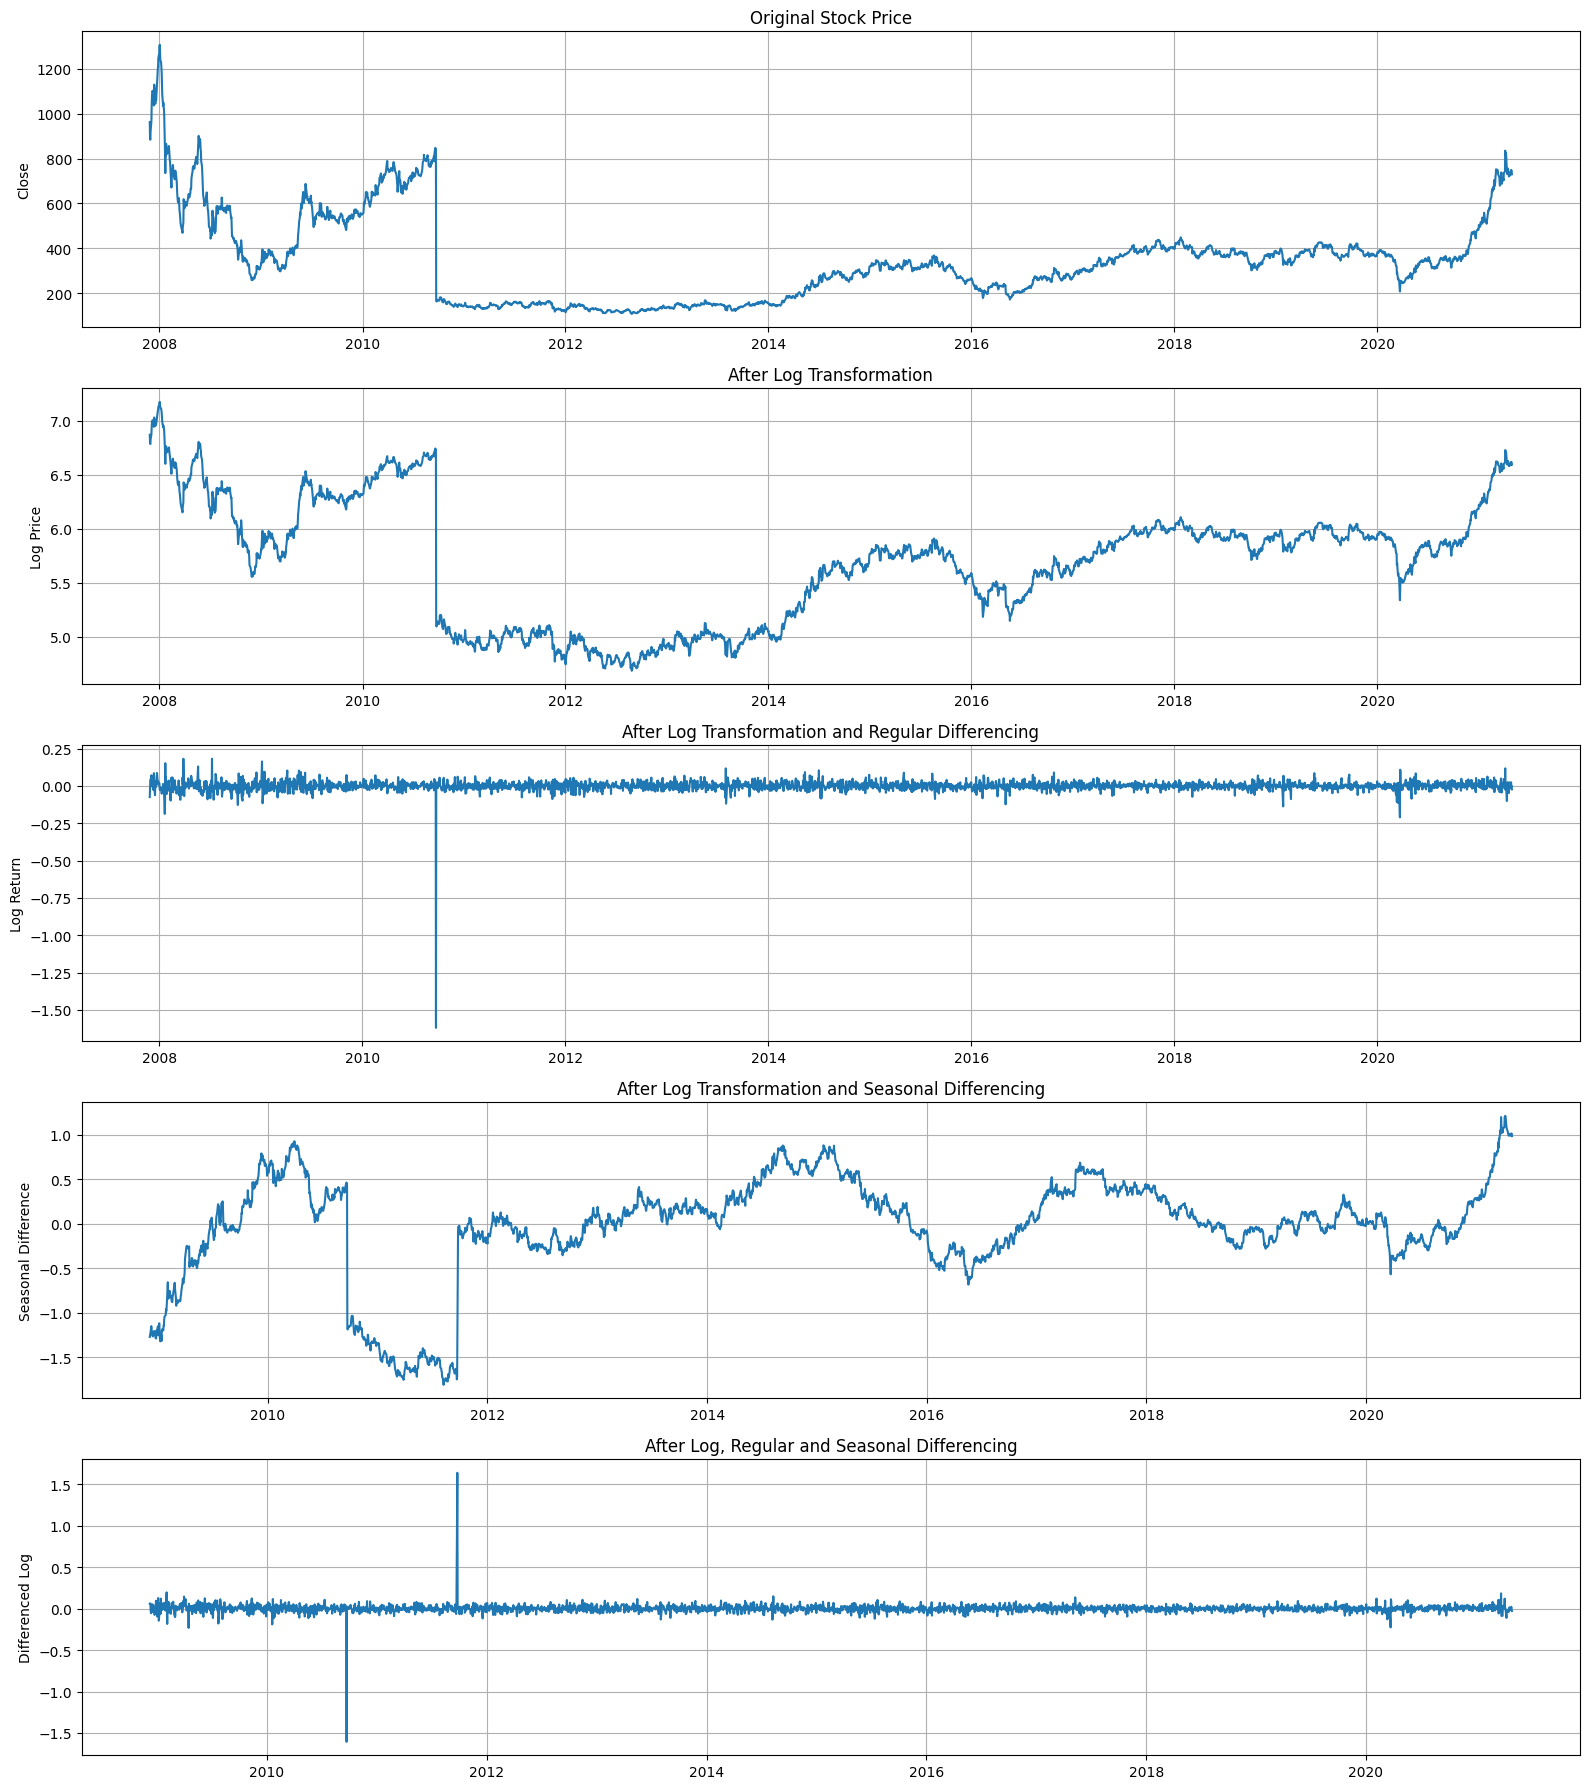

In [3]:

import matplotlib.pyplot as plt
import pandas as pd
import numpy as np

data = pd.read_csv('/content/ADANIPORTS-selected-columns.csv')

data['Date'] = pd.to_datetime(data['Date'])
data = data.sort_values('Date')
data = data.drop_duplicates(subset='Date', keep='last')
data = data.set_index('Date')

data['Close'] = pd.to_numeric(data['Close'], errors='coerce')
data = data.dropna(subset=['Close'])

data['Log'] = np.log(data['Close'])

data['Log_Diff'] = data['Log'].diff()

data['Log_Seasonal_Diff'] = data['Log'].diff(252)

data['Log_Regular_Seasonal_Diff'] = (
    data['Log'].diff().diff(252)
)

plt.figure(figsize=(16, 18))

plt.subplot(5, 1, 1)
plt.plot(data['Close'])
plt.title('Original Stock Price')
plt.ylabel('Close')
plt.grid(True)

plt.subplot(5, 1, 2)
plt.plot(data['Log'])
plt.title('After Log Transformation')
plt.ylabel('Log Price')
plt.grid(True)

plt.subplot(5, 1, 3)
plt.plot(data['Log_Diff'])
plt.title('After Log Transformation and Regular Differencing')
plt.ylabel('Log Return')
plt.grid(True)

plt.subplot(5, 1, 4)
plt.plot(data['Log_Seasonal_Diff'])
plt.title('After Log Transformation and Seasonal Differencing')
plt.ylabel('Seasonal Difference')
plt.grid(True)

plt.subplot(5, 1, 5)
plt.plot(data['Log_Regular_Seasonal_Diff'])
plt.title('After Log, Regular and Seasonal Differencing')
plt.ylabel('Differenced Log')
plt.grid(True)

plt.tight_layout()
plt.show()
